# Thống kê dữ liệu VisDrone2019-MOT

Notebook phân tích chi tiết bộ dữ liệu **VisDrone2019-MOT** (train / val / test-dev) phục vụ huấn luyện detector (RF-DETR, YOLO11, Faster R-CNN) và đánh giá tracking.

**Nội dung**

1. Thiết lập và cấu trúc thư mục
2. Kiểm tra toàn vẹn dữ liệu (ảnh, đánh số frame, file nhãn)
3. Đọc nhãn và tổng quan theo split
4. Thống kê theo chuỗi video
5. Phân bố lớp
6. Kích thước box (gốc và sau khi resize về input của mô hình)
7. Tỉ lệ khung hình (aspect ratio)
8. Mật độ đối tượng trên mỗi frame
9. Che khuất và bị cắt mép
10. Phân bố không gian
11. Thống kê quỹ đạo (track): độ dài, đứt đoạn, chuyển động, IoU giữa hai frame liên tiếp
12. Vùng ignored
13. Chất lượng nhãn
14. Độ dư thừa giữa các frame liên tiếp và ảnh hưởng của việc lấy mẫu 1/2
15. Ảnh minh họa
16. Tổng kết và khuyến nghị khi train

Quy ước log: `[+]` là mục chính, `[-]` là chi tiết bên trong.

## 1. Thiết lập

In [1]:
import os
import glob
import json
import warnings
from collections import Counter
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")

DATA_ROOT = Path(os.environ.get("VISDRONE_ROOT", "../../data/raw")).resolve()
FIG_DIR = Path("../../outputs/eda/figures").resolve()
TABLE_DIR = Path("../../outputs/eda/tables").resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train", "val", "test-dev"]
CLASS_NAMES = {
    0: "ignored", 1: "pedestrian", 2: "people", 3: "bicycle", 4: "car", 5: "van",
    6: "truck", 7: "tricycle", 8: "awning-tricycle", 9: "bus", 10: "motor", 11: "others",
}
OBJ_CLASSES = list(range(1, 11))            # classes used to train the detector
TRACK_CLASSES = [1, 4, 5, 6, 9]             # classes evaluated in VisDrone-MOT
MODEL_RES = [576, 640, 768, 1024]           # long-side input sizes to simulate
PALETTE = dict(zip(SPLITS, sns.color_palette("Set2", 3)))
N_WORKERS = min(32, os.cpu_count() or 4)


def log(msg, level=0):
    """Human-readable log: [+] for main items, [-] for details."""
    print("    " * level + ("[+] " if level == 0 else "[-] ") + msg)


def fmt(n):
    return f"{n:,}".replace(",", ".") if isinstance(n, (int, np.integer)) else f"{n:,.2f}"


def pct(a, b):
    return f"{100 * a / max(b, 1):.1f}%"


def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    log(f"Saved figure {path.name}", 1)


def save_table(df, name):
    path = TABLE_DIR / f"{name}.csv"
    df.to_csv(path)
    log(f"Saved table {path.name}", 1)


log(f"Data root: {DATA_ROOT}")
for split in SPLITS:
    d = DATA_ROOT / f"VisDrone2019-MOT-{split}"
    log(f"{split}: {'found' if d.exists() else 'MISSING'} ({d.name})", 1)
log(f"Workers: {N_WORKERS}")

[+] Data root: /home/vpcuser/AI_LAB/ntrthanh/rfdetr/data/raw
    [-] train: found (VisDrone2019-MOT-train)
    [-] val: found (VisDrone2019-MOT-val)
    [-] test-dev: found (VisDrone2019-MOT-test-dev)
[+] Workers: 32


In [2]:
def du(path):
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file())


log("Directory layout")
for split in SPLITS:
    d = DATA_ROOT / f"VisDrone2019-MOT-{split}"
    seqs = sorted(p.name for p in (d / "sequences").iterdir())
    anns = sorted(p.name for p in (d / "annotations").glob("*.txt"))
    log(f"VisDrone2019-MOT-{split}/  ({du(d) / 1e9:.2f} GB)", 1)
    log(f"sequences/   {len(seqs)} folders, e.g. {seqs[0]}/0000001.jpg", 2)
    log(f"annotations/ {len(anns)} files,   e.g. {anns[0]}", 2)

[+] Directory layout


    [-] VisDrone2019-MOT-train/  (8.13 GB)
        [-] sequences/   56 folders, e.g. uav0000013_00000_v/0000001.jpg
        [-] annotations/ 56 files,   e.g. uav0000013_00000_v.txt
    [-] VisDrone2019-MOT-val/  (1.64 GB)
        [-] sequences/   7 folders, e.g. uav0000086_00000_v/0000001.jpg
        [-] annotations/ 7 files,   e.g. uav0000086_00000_v.txt
    [-] VisDrone2019-MOT-test-dev/  (2.31 GB)
        [-] sequences/   17 folders, e.g. uav0000009_03358_v/0000001.jpg
        [-] annotations/ 17 files,   e.g. uav0000009_03358_v.txt


Mỗi split gồm `sequences/<seq>/<frame:07d>.jpg` và `annotations/<seq>.txt`. Mỗi dòng nhãn có 10 cột:

| Cột | Tên | Ý nghĩa |
|---|---|---|
| 1 | `frame` | Số thứ tự frame, trùng với tên ảnh |
| 2 | `track_id` | ID đối tượng, giữ nguyên qua các frame |
| 3–6 | `x, y, w, h` | Box theo pixel ảnh gốc |
| 7 | `score` | Trong GT: 1 = tính khi đánh giá, 0 = bỏ qua |
| 8 | `cls` | Lớp (0 = ignored region, 11 = others) |
| 9 | `trunc` | Bị cắt mép: 0 không, 1 một phần |
| 10 | `occ` | Bị che: 0 không, 1 một phần, 2 nhiều |

## 2. Kiểm tra toàn vẹn dữ liệu

In [3]:
def check_image(path):
    """Return (path, width, height, ok). ok=False if header unreadable or JPEG end marker missing."""
    try:
        with Image.open(path) as im:
            w, h = im.size
            im.verify()
        with open(path, "rb") as f:
            f.seek(-2, os.SEEK_END)
            ok = f.read(2) == b"\xff\xd9"
        return str(path), w, h, ok
    except Exception:
        return str(path), -1, -1, False


all_images = []
for split in SPLITS:
    for p in sorted((DATA_ROOT / f"VisDrone2019-MOT-{split}" / "sequences").glob("*/*.jpg")):
        all_images.append((split, p.parent.name, int(p.stem), p))

with ProcessPoolExecutor(N_WORKERS) as ex:
    results = list(ex.map(check_image, [x[3] for x in all_images], chunksize=256))

img_df = pd.DataFrame(
    [(s, q, f, w, h, ok) for (s, q, f, _), (_, w, h, ok) in zip(all_images, results)],
    columns=["split", "seq", "frame", "img_w", "img_h", "ok"],
)

log(f"Checked {fmt(len(img_df))} images")
bad = img_df[~img_df.ok]
log(f"Corrupted or truncated images: {len(bad)}", 1)
for r in bad.head(10).itertuples():
    log(f"{r.split}/{r.seq}/{r.frame:07d}.jpg", 2)

[+] Checked 33.682 images
    [-] Corrupted or truncated images: 0


In [4]:
log("Per-sequence consistency")
issues = 0
seq_res = img_df.groupby(["split", "seq"]).agg(
    n_frames=("frame", "size"), f_min=("frame", "min"), f_max=("frame", "max"),
    n_res=("img_w", lambda s: s.nunique()), img_w=("img_w", "first"), img_h=("img_h", "first"),
).reset_index()

for split in SPLITS:
    s = seq_res[seq_res.split == split]
    ann_files = {p.stem for p in (DATA_ROOT / f"VisDrone2019-MOT-{split}" / "annotations").glob("*.txt")}
    missing_ann = set(s.seq) - ann_files
    orphan_ann = ann_files - set(s.seq)
    gaps = s[(s.f_min != 1) | (s.f_max != s.n_frames)]
    multi_res = s[s.n_res > 1]
    log(f"{split}", 1)
    log(f"sequences without annotation file: {len(missing_ann)}", 2)
    log(f"annotation files without sequence: {len(orphan_ann)}", 2)
    log(f"sequences with non-contiguous frame numbering: {len(gaps)}", 2)
    log(f"sequences with mixed resolutions: {len(multi_res)}", 2)
    issues += len(missing_ann) + len(orphan_ann) + len(gaps) + len(multi_res)
log(f"Total structural issues: {issues}")

[+] Per-sequence consistency
    [-] train
        [-] sequences without annotation file: 0
        [-] annotation files without sequence: 0
        [-] sequences with non-contiguous frame numbering: 0
        [-] sequences with mixed resolutions: 0
    [-] val
        [-] sequences without annotation file: 0
        [-] annotation files without sequence: 0
        [-] sequences with non-contiguous frame numbering: 0
        [-] sequences with mixed resolutions: 0
    [-] test-dev
        [-] sequences without annotation file: 0
        [-] annotation files without sequence: 0
        [-] sequences with non-contiguous frame numbering: 0
        [-] sequences with mixed resolutions: 0
[+] Total structural issues: 0


**Nhận xét.**

Toàn bộ 33.682 ảnh đều đọc được và có marker kết thúc JPEG, nên không có ảnh hỏng hay bị cắt cụt trong quá trình tải. Mỗi chuỗi có đúng một file nhãn, frame được đánh số liên tục từ 1 và mọi ảnh trong cùng một chuỗi có cùng độ phân giải.

Như vậy dữ liệu đầy đủ và nhất quán, có thể dùng trực tiếp để tạo nhãn COCO hoặc YOLO mà không cần sửa lại cấu trúc thư mục.

## 3. Đọc nhãn và tổng quan theo split

In [5]:
COLS = ["frame", "track_id", "x", "y", "w", "h", "score", "cls", "trunc", "occ"]
frames_df = []
for split in SPLITS:
    for ann in sorted((DATA_ROOT / f"VisDrone2019-MOT-{split}" / "annotations").glob("*.txt")):
        d = pd.read_csv(ann, header=None, names=COLS, usecols=range(10))
        d.insert(0, "seq", ann.stem)
        d.insert(0, "split", split)
        frames_df.append(d)
ann_all = pd.concat(frames_df, ignore_index=True)

res = seq_res.set_index(["split", "seq"])[["img_w", "img_h"]]
ann_all = ann_all.join(res, on=["split", "seq"])
ann_all["cls_name"] = ann_all.cls.map(CLASS_NAMES)
ann_all["area"] = ann_all.w * ann_all.h
ann_all["sqrt_area"] = np.sqrt(ann_all.area)
ann_all["aspect"] = ann_all.w / ann_all.h.replace(0, np.nan)
ann_all["rel_area"] = ann_all.area / (ann_all.img_w * ann_all.img_h)
ann_all["cx"] = (ann_all.x + ann_all.w / 2) / ann_all.img_w
ann_all["cy"] = (ann_all.y + ann_all.h / 2) / ann_all.img_h
ann_all["size_bin"] = pd.cut(ann_all.area, [-1, 32 ** 2, 96 ** 2, np.inf], labels=["small", "medium", "large"])

ign = ann_all[ann_all.cls == 0].copy()
obj = ann_all[ann_all.cls.isin(OBJ_CLASSES)].copy()

log(f"Parsed {fmt(len(ann_all))} annotation rows")
log(f"object boxes (cls 1-10): {fmt(len(obj))}", 1)
log(f"ignored regions (cls 0): {fmt(len(ign))}", 1)
log(f"others (cls 11):         {fmt(int((ann_all.cls == 11).sum()))}", 1)

[+] Parsed 1.621.186 annotation rows
    [-] object boxes (cls 1-10): 1.527.447
    [-] ignored regions (cls 0): 89.835
    [-] others (cls 11):         3.904


In [6]:
overview = []
for split in SPLITS:
    o = obj[obj.split == split]
    im = img_df[img_df.split == split]
    tracks = o.groupby(["seq", "track_id"]).ngroups
    overview.append({
        "split": split,
        "sequences": im.seq.nunique(),
        "frames": len(im),
        "boxes": len(o),
        "tracks": tracks,
        "boxes/frame": len(o) / len(im),
        "ignored regions": int((ign.split == split).sum()),
        "resolutions": im.groupby(["img_w", "img_h"]).ngroups,
    })
overview = pd.DataFrame(overview).set_index("split")
overview.loc["total"] = overview.sum(numeric_only=True)
overview.loc["total", "boxes/frame"] = overview.loc["total", "boxes"] / overview.loc["total", "frames"]

log("Split overview")
for split, r in overview.iterrows():
    log(f"{split:<9} {int(r.sequences):>3} seqs  {fmt(int(r.frames)):>7} frames  "
        f"{fmt(int(r.boxes)):>10} boxes  {fmt(int(r.tracks)):>6} tracks  {r['boxes/frame']:.1f} boxes/frame", 1)
save_table(overview, "01_split_overview")
overview.style.format(precision=1, thousands=".")

[+] Split overview
    [-] train      56 seqs   24.201 frames   1.105.516 boxes   7.342 tracks  45.7 boxes/frame
    [-] val         7 seqs    2.846 frames     114.132 boxes     758 tracks  40.1 boxes/frame
    [-] test-dev   17 seqs    6.635 frames     307.799 boxes   2.293 tracks  46.4 boxes/frame
    [-] total      80 seqs   33.682 frames   1.527.447 boxes  10.393 tracks  45.3 boxes/frame
    [-] Saved table 01_split_overview.csv


,sequences,frames,boxes,tracks,boxes/frame,ignored regions,resolutions
split,,,,,,,
train,56,24.201,1.105.516,7.342,45.7,62.369,6
val,7,2.846,114.132,758,40.1,3.994,5
test-dev,17,6.635,307.799,2.293,46.4,23.472,7
total,80,33.682,1.527.447,10.393,45.3,89.835,18


**Nhận xét.**

Bộ dữ liệu gồm 80 chuỗi, 33.682 frame, khoảng 1,53 triệu box thuộc 10 lớp và 10.393 quỹ đạo. Mật độ trung bình khoảng 40 đến 46 box mỗi frame ở cả ba split, cao hơn nhiều so với COCO (khoảng 7 box mỗi ảnh).

Tập val khá nhỏ với 7 chuỗi và 2.846 frame, nên chỉ số trên val sẽ dao động đáng kể giữa các epoch. Khi chọn checkpoint nên xem xu hướng qua nhiều epoch thay vì chỉ lấy một điểm cao nhất.

## 4. Thống kê theo chuỗi video

In [7]:
seq_stats = obj.groupby(["split", "seq"]).agg(
    boxes=("frame", "size"),
    tracks=("track_id", "nunique"),
    median_sqrt_area=("sqrt_area", "median"),
    pct_small=("size_bin", lambda s: 100 * (s == "small").mean()),
).join(seq_res.set_index(["split", "seq"])[["n_frames", "img_w", "img_h"]])
seq_stats["boxes/frame"] = seq_stats.boxes / seq_stats.n_frames
seq_stats["resolution"] = seq_stats.img_w.astype(str) + "x" + seq_stats.img_h.astype(str)
seq_stats = seq_stats[["n_frames", "resolution", "boxes", "tracks", "boxes/frame", "median_sqrt_area", "pct_small"]]
save_table(seq_stats, "02_sequence_stats")

log("Sequence length (frames)")
for split in SPLITS:
    n = seq_stats.loc[split].n_frames
    log(f"{split:<9} min {n.min():>4}  median {int(n.median()):>4}  max {n.max():>4}  total {fmt(int(n.sum()))}", 1)

log("Resolutions (number of sequences)")
for split in SPLITS:
    rc = seq_stats.loc[split].resolution.value_counts()
    log(f"{split}: " + ", ".join(f"{k} x{v}" for k, v in rc.items()), 1)

    [-] Saved table 02_sequence_stats.csv
[+] Sequence length (frames)
    [-] train     min   58  median  383  max 1424  total 24.201
    [-] val       min  184  median  349  max  978  total 2.846
    [-] test-dev  min  146  median  312  max 1000  total 6.635
[+] Resolutions (number of sequences)
    [-] train: 1904x1071 x30, 1344x756 x11, 2688x1512 x11, 2720x1530 x2, 1920x1080 x1, 1360x765 x1
    [-] val: 1344x756 x2, 1904x1071 x2, 2720x1530 x1, 2688x1512 x1, 3840x2160 x1
    [-] test-dev: 1360x765 x5, 1920x1080 x3, 960x540 x3, 1344x756 x2, 1904x1071 x2, 680x382 x1, 2720x1530 x1


    [-] Saved figure 04_sequences.png


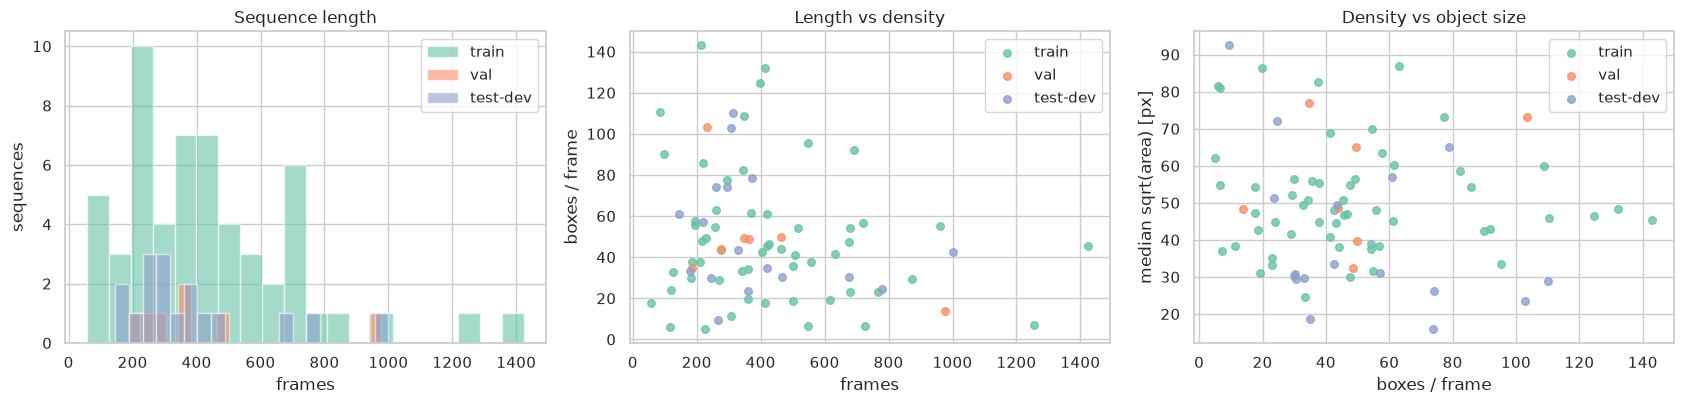

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for split in SPLITS:
    s = seq_stats.loc[split]
    axes[0].hist(s.n_frames, bins=20, alpha=0.6, label=split, color=PALETTE[split])
    axes[1].scatter(s.n_frames, s["boxes/frame"], label=split, color=PALETTE[split], s=30, alpha=0.8)
    axes[2].scatter(s["boxes/frame"], s.median_sqrt_area, label=split, color=PALETTE[split], s=30, alpha=0.8)
axes[0].set(title="Sequence length", xlabel="frames", ylabel="sequences")
axes[1].set(title="Length vs density", xlabel="frames", ylabel="boxes / frame")
axes[2].set(title="Density vs object size", xlabel="boxes / frame", ylabel="median sqrt(area) [px]")
for a in axes:
    a.legend()
plt.tight_layout()
save_fig(fig, "04_sequences")
plt.show()

display(seq_stats.sort_values("boxes/frame", ascending=False).head(10).style.format(precision=1))

**Nhận xét.**

Độ dài các chuỗi chênh lệch lớn, riêng train dao động từ 58 đến 1.424 frame, vì vậy một vài chuỗi dài sẽ đóng góp phần lớn số ảnh huấn luyện. Dữ liệu có 7 độ phân giải khác nhau, từ 680×382 đến 3840×2160. Train chủ yếu là 1904×1071 và 2688×1512, trong khi test-dev có nhiều ảnh nhỏ hơn như 960×540 và 1360×765, nên khi tạo nhãn COCO bắt buộc ghi kích thước theo từng ảnh.

Biểu đồ mật độ theo kích thước cho thấy các chuỗi đông nhất thường cũng là các chuỗi có đối tượng nhỏ nhất. Hai khó khăn "đông" và "nhỏ" vì thế thường xuất hiện cùng lúc.

## 5. Phân bố lớp

In [9]:
cls_counts = obj.pivot_table(index="cls_name", columns="split", values="frame", aggfunc="size", fill_value=0)
cls_counts = cls_counts.reindex([CLASS_NAMES[c] for c in OBJ_CLASSES])[SPLITS]
cls_pct = 100 * cls_counts / cls_counts.sum()
cls_tracks = obj.groupby(["split", "cls_name"]).apply(lambda d: d.groupby(["seq", "track_id"]).ngroups).unstack(0)
cls_tracks = cls_tracks.reindex(cls_counts.index)[SPLITS]

table = pd.concat({"boxes": cls_counts, "%": cls_pct.round(1), "tracks": cls_tracks}, axis=1)
save_table(table, "03_class_distribution")

log("Class distribution (boxes, share, tracks)")
for name in cls_counts.index:
    tag = " *track*" if name in [CLASS_NAMES[c] for c in TRACK_CLASSES] else ""
    parts = [f"{s}: {fmt(int(cls_counts.loc[name, s])):>8} ({cls_pct.loc[name, s]:4.1f}%)" for s in SPLITS]
    log(f"{name:<16}{tag:<8} " + "  ".join(parts), 1)
imb = cls_counts["train"].max() / cls_counts["train"].min()
log(f"Imbalance ratio in train (largest / smallest class): {imb:.0f}x")
table

    [-] Saved table 03_class_distribution.csv
[+] Class distribution (boxes, share, tracks)
    [-] pedestrian       *track* train:  234.305 (21.2%)  val:   32.404 (28.4%)  test-dev:  106.184 (34.5%)
    [-] people                   train:   94.396 ( 8.5%)  val:   17.908 (15.7%)  test-dev:   33.999 (11.0%)
    [-] bicycle                  train:   40.255 ( 3.6%)  val:    6.022 ( 5.3%)  test-dev:    3.637 ( 1.2%)
    [-] car              *track* train:  505.301 (45.7%)  val:   31.821 (27.9%)  test-dev:   99.727 (32.4%)
    [-] van              *track* train:   46.940 ( 4.2%)  val:    6.842 ( 6.0%)  test-dev:   11.223 ( 3.6%)
    [-] truck            *track* train:   30.498 ( 2.8%)  val:    1.359 ( 1.2%)  test-dev:   13.708 ( 4.5%)
    [-] tricycle                 train:   28.338 ( 2.6%)  val:    3.769 ( 3.3%)  test-dev:    6.721 ( 2.2%)
    [-] awning-tricycle          train:   13.011 ( 1.2%)  val:    1.718 ( 1.5%)  test-dev:    4.354 ( 1.4%)
    [-] bus              *track* train:    9

boxes                     %                tracks              
split             train    val test-dev train   val test-dev  train  val test-dev
cls_name                                                                         
pedestrian       234305  32404   106184  21.2  28.4     34.5   1829  227      766
people            94396  17908    33999   8.5  15.7     11.0    853  117      283
bicycle           40255   6022     3637   3.6   5.3      1.2    323   48       33
car              505301  31821    99727  45.7  27.9     32.4   3017  201      779
van               46940   6842    11223   4.2   6.0      3.6    295   40       68
truck             30498   1359    13708   2.8   1.2      4.5    159    8       72
tricycle          28338   3769     6721   2.6   3.3      2.2    215   20       51
awning-tricycle   13011   1718     4354   1.2   1.5      1.4     79   12       36
bus                9653    264     1536   0.9   0.2      0.5     55    3       12
motor            102819  12025    26710   9.3  10.5      8.7    749  100      270

    [-] Saved figure 05_class_distribution.png


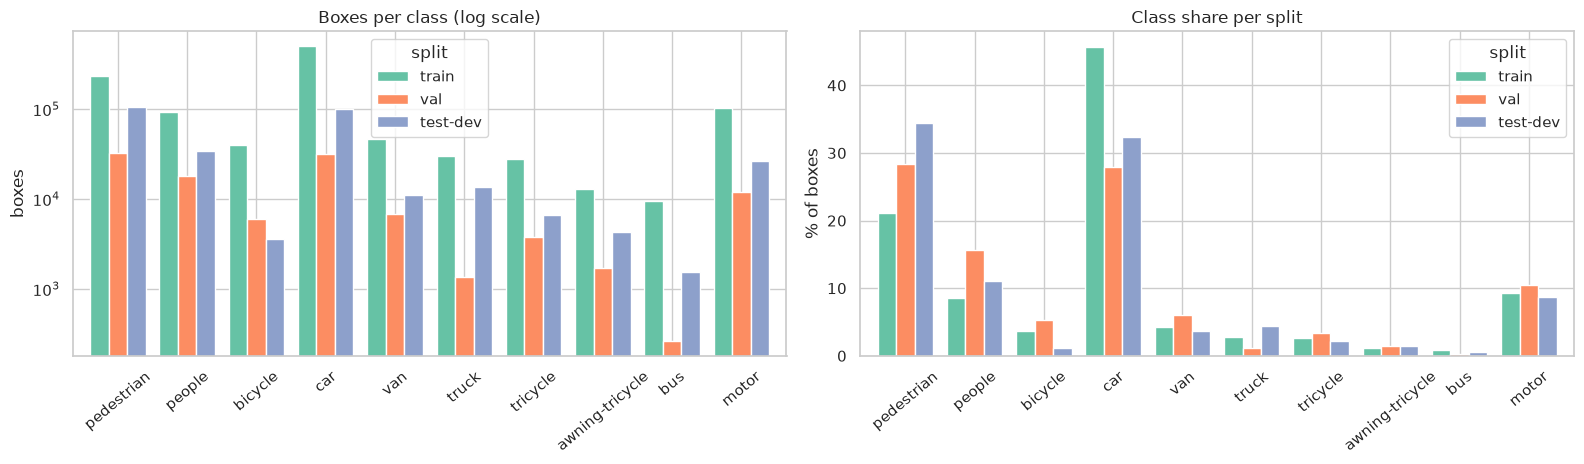

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
cls_counts.plot.bar(ax=axes[0], logy=True, color=[PALETTE[s] for s in SPLITS], width=0.8)
axes[0].set(title="Boxes per class (log scale)", xlabel="", ylabel="boxes")
cls_pct.plot.bar(ax=axes[1], color=[PALETTE[s] for s in SPLITS], width=0.8)
axes[1].set(title="Class share per split", xlabel="", ylabel="% of boxes")
for a in axes:
    a.tick_params(axis="x", rotation=40)
plt.tight_layout()
save_fig(fig, "05_class_distribution")
plt.show()

**Nhận xét.**

Dữ liệu mất cân bằng lớp rất mạnh. Trong train, `car` chiếm 45,7% số box còn `bus` chỉ chiếm 0,9%, chênh lệch khoảng 52 lần. Phân bố lớp cũng khác nhau giữa các split, khi val và test-dev có tỉ lệ `pedestrian` cao hơn hẳn train (28 đến 35% so với 21%) còn tỉ lệ `car` thấp hơn. Một mô hình học thiên về `car` vì vậy có thể cho kết quả trên val và test-dev thấp hơn kỳ vọng.

Trong 5 lớp dùng cho tracking, `bus` và `truck` có rất ít mẫu, chẳng hạn val chỉ có 264 box `bus`. AP và HOTA của hai lớp này sẽ có phương sai lớn và nên được báo cáo kèm số mẫu. Nếu AP các lớp hiếm quá thấp có thể thử repeat-factor sampling, nhưng baseline nên giữ cấu hình chuẩn để việc so sánh giữa 3 detector công bằng.

## 6. Kích thước box

### 6.1. Theo kích thước ảnh gốc (chuẩn COCO: small < 32², medium < 96², large ≥ 96²)

In [11]:
size_tab = obj.pivot_table(index="split", columns="size_bin", values="frame", aggfunc="size").reindex(SPLITS)
size_pct = (100 * size_tab.div(size_tab.sum(axis=1), axis=0)).round(1)

log("COCO size bins at original resolution")
for split in SPLITS:
    log(f"{split:<9} small {size_pct.loc[split, 'small']:5.1f}%  medium {size_pct.loc[split, 'medium']:5.1f}%  "
        f"large {size_pct.loc[split, 'large']:5.1f}%", 1)

log("Box side length sqrt(area) in pixels (original resolution)")
for split in SPLITS:
    q = obj[obj.split == split].sqrt_area.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    log(f"{split:<9} p5 {q[0.05]:5.1f}  p25 {q[0.25]:5.1f}  median {q[0.5]:5.1f}  p75 {q[0.75]:5.1f}  p95 {q[0.95]:6.1f}", 1)

per_cls_size = obj[obj.split == "train"].groupby("cls_name").agg(
    median_w=("w", "median"), median_h=("h", "median"), median_sqrt_area=("sqrt_area", "median"),
    pct_small=("size_bin", lambda s: 100 * (s == "small").mean()),
).reindex([CLASS_NAMES[c] for c in OBJ_CLASSES])
save_table(per_cls_size, "04_class_size_train")
per_cls_size.style.format(precision=1)

[+] COCO size bins at original resolution
    [-] train     small  24.9%  medium  63.5%  large  11.6%
    [-] val       small  19.2%  medium  69.5%  large  11.3%
    [-] test-dev  small  47.8%  medium  45.4%  large   6.8%
[+] Box side length sqrt(area) in pixels (original resolution)
    [-] train     p5  19.7  p25  32.0  median  45.8  p75  67.9  p95  130.2
    [-] val       p5  22.6  p25  35.5  median  52.4  p75  73.2  p95  130.7
    [-] test-dev  p5  14.3  p25  21.9  median  33.4  p75  56.1  p95  106.0


    [-] Saved table 04_class_size_train.csv


,median_w,median_h,median_sqrt_area,pct_small
cls_name,,,,
pedestrian,24.0,52.0,35.7,39.4
people,28.0,47.0,36.0,39.7
bicycle,43.0,43.0,41.4,24.4
car,67.0,48.0,57.0,16.4
van,55.0,46.0,49.8,21.5
truck,79.0,68.0,73.5,9.4
tricycle,62.0,53.0,57.6,16.6
awning-tricycle,48.0,44.0,45.9,30.9
bus,121.0,103.0,113.4,4.1


    [-] Saved figure 06_box_size.png


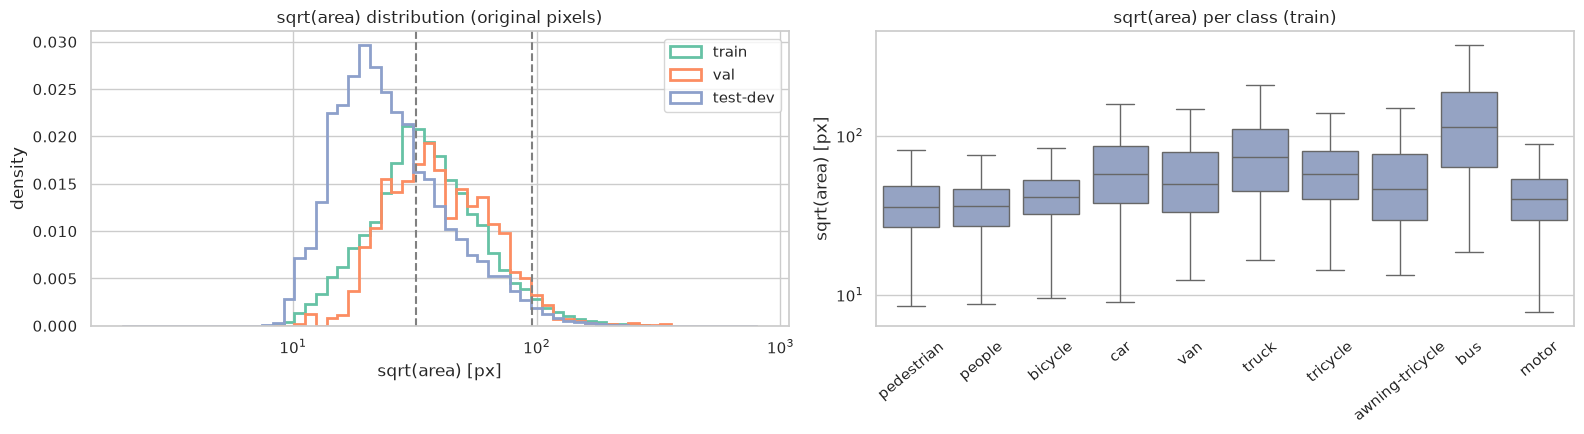

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
bins = np.logspace(np.log10(2), np.log10(800), 60)
for split in SPLITS:
    axes[0].hist(obj[obj.split == split].sqrt_area, bins=bins, density=True, histtype="step", lw=2,
                 label=split, color=PALETTE[split])
for v, t in [(32, "32"), (96, "96")]:
    axes[0].axvline(v, ls="--", c="gray")
axes[0].set(xscale="log", title="sqrt(area) distribution (original pixels)", xlabel="sqrt(area) [px]", ylabel="density")
axes[0].legend()
sns.boxplot(data=obj[obj.split == "train"], x="cls_name", y="sqrt_area", order=[CLASS_NAMES[c] for c in OBJ_CLASSES],
            ax=axes[1], showfliers=False, color="#8da0cb")
axes[1].set(yscale="log", title="sqrt(area) per class (train)", xlabel="", ylabel="sqrt(area) [px]")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout()
save_fig(fig, "06_box_size")
plt.show()

### 6.2. Sau khi resize cạnh dài về input của mô hình

In [13]:
rows = []
for R in MODEL_RES:
    k = R / obj[["img_w", "img_h"]].max(axis=1)
    side = np.minimum(obj.w, obj.h) * k
    area = obj.area * k ** 2
    for split in SPLITS:
        m = (obj.split == split).values
        rows.append({
            "split": split, "input": R,
            "min side < 4px": 100 * (side[m] < 4).mean(),
            "min side < 8px": 100 * (side[m] < 8).mean(),
            "min side < 16px": 100 * (side[m] < 16).mean(),
            "small (<32²)": 100 * (area[m] < 32 ** 2).mean(),
            "median sqrt(area)": np.sqrt(area[m]).median(),
        })
resized = pd.DataFrame(rows).set_index(["input", "split"])
save_table(resized, "05_resized_box_size")

log("Box size after resizing the long side to the model input")
for R in MODEL_RES:
    log(f"input {R}", 1)
    for split in SPLITS:
        r = resized.loc[(R, split)]
        log(f"{split:<9} <8px {r['min side < 8px']:5.1f}%  <16px {r['min side < 16px']:5.1f}%  "
            f"small {r['small (<32²)']:5.1f}%  median side {r['median sqrt(area)']:.1f}px", 2)
resized.style.format(precision=1)

    [-] Saved table 05_resized_box_size.csv
[+] Box size after resizing the long side to the model input
    [-] input 576
        [-] train     <8px  27.9%  <16px  75.0%  small  91.8%  median side 13.7px
        [-] val       <8px  24.3%  <16px  75.8%  small  94.4%  median side 14.7px
        [-] test-dev  <8px  24.3%  <16px  70.5%  small  90.8%  median side 14.4px
    [-] input 640
        [-] train     <8px  22.0%  <16px  69.3%  small  89.0%  median side 15.2px
        [-] val       <8px  19.0%  <16px  68.2%  small  91.1%  median side 16.3px
        [-] test-dev  <8px  17.8%  <16px  64.0%  small  87.8%  median side 16.0px
    [-] input 768
        [-] train     <8px  12.9%  <16px  56.2%  small  83.4%  median side 18.2px
        [-] val       <8px  11.7%  <16px  53.9%  small  84.2%  median side 19.6px
        [-] test-dev  <8px  11.3%  <16px  52.7%  small  80.1%  median side 19.2px
    [-] input 1024
        [-] train     <8px   4.3%  <16px  36.0%  small  69.2%  median side 24.3px
  

    [-] Saved figure 06_resized_small_boxes.png


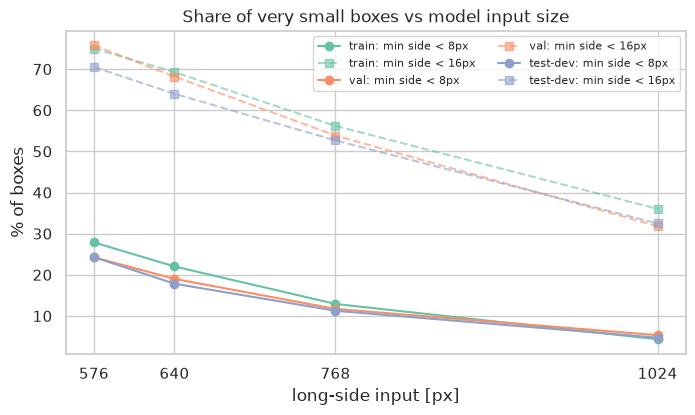

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for split in SPLITS:
    ax.plot(MODEL_RES, [resized.loc[(R, split), "min side < 8px"] for R in MODEL_RES], "o-",
            label=f"{split}: min side < 8px", color=PALETTE[split])
    ax.plot(MODEL_RES, [resized.loc[(R, split), "min side < 16px"] for R in MODEL_RES], "s--",
            label=f"{split}: min side < 16px", color=PALETTE[split], alpha=0.6)
ax.set(title="Share of very small boxes vs model input size", xlabel="long-side input [px]", ylabel="% of boxes")
ax.set_xticks(MODEL_RES)
ax.legend(fontsize=8, ncol=2)
save_fig(fig, "06_resized_small_boxes")
plt.show()

**Nhận xét.**

Ngay ở độ phân giải gốc, đối tượng đã nhỏ. Cạnh trung vị của box khoảng 46 px ở train và chỉ 33 px ở test-dev, trong đó 47,8% box ở test-dev thuộc nhóm small, gần gấp đôi train (24,9%). Đây là nguyên nhân khiến mAP trên test-dev sẽ thấp hơn val một cách đáng kể. Các lớp nhỏ nhất là `pedestrian`, `people`, `motor` và `bicycle`, còn `bus` và `truck` là lớn nhất.

Vấn đề trở nên nghiêm trọng sau khi resize về kích thước đầu vào của mô hình. Ở 576, cạnh trung vị chỉ còn khoảng 14 px và 27,9% box train có cạnh ngắn dưới 8 px, tức là phần lớn đối tượng nhỏ hơn một patch của backbone ViT. Khi tăng lên 1024, tỉ lệ này giảm xuống khoảng 4 đến 5% và cạnh trung vị tăng lên khoảng 25 px.

Độ phân giải đầu vào vì vậy là yếu tố ảnh hưởng mạnh nhất đến kết quả trên bộ dữ liệu này. Với RF-DETR nên dùng khoảng 896 đến 1024 nếu VRAM cho phép, bằng cách giảm batch và tăng `grad_accum_steps`. Nếu giữ 576 thì cần nêu rõ hạn chế này trong báo cáo, kèm AP_small, và ghi rõ input size của từng detector khi so sánh vì Faster R-CNN với cạnh dài 1333 sẽ có lợi thế rõ rệt.

## 7. Tỉ lệ khung hình (w/h)

[+] Aspect ratio w/h per class (train): median [p5, p95]


    [-] pedestrian       0.47  [0.33, 0.75]
    [-] people           0.61  [0.41, 1.00]
    [-] bicycle          0.95  [0.45, 1.92]
    [-] car              1.25  [0.73, 2.69]
    [-] van              1.11  [0.65, 2.04]
    [-] truck            1.08  [0.70, 2.53]
    [-] tricycle         1.10  [0.60, 2.11]
    [-] awning-tricycle  1.00  [0.62, 1.78]
    [-] bus              1.03  [0.58, 3.58]
    [-] motor            0.80  [0.46, 1.71]
    [-] Saved table 06_aspect_ratio_train.csv


    [-] Saved figure 07_aspect_ratio.png


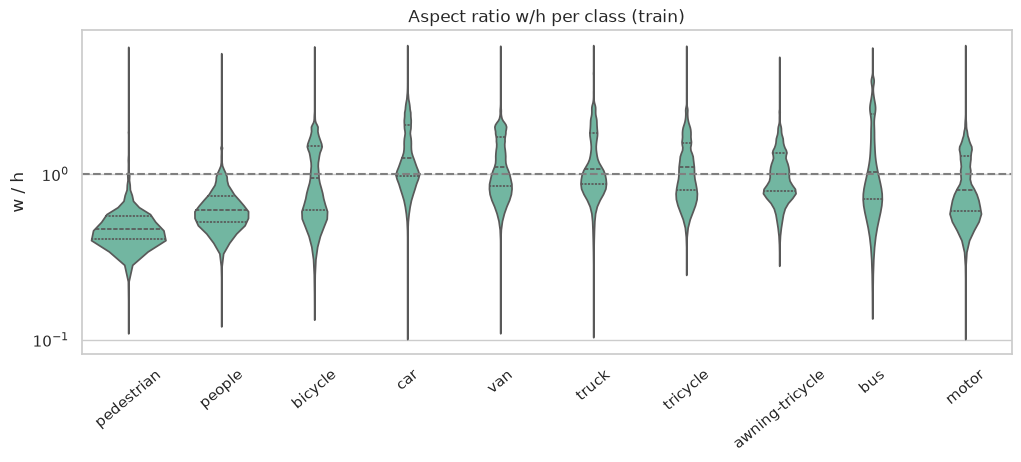

In [15]:
log("Aspect ratio w/h per class (train): median [p5, p95]")
asp = obj[obj.split == "train"].groupby("cls_name").aspect.quantile([0.05, 0.5, 0.95]).unstack()
asp = asp.reindex([CLASS_NAMES[c] for c in OBJ_CLASSES])
for name, r in asp.iterrows():
    log(f"{name:<16} {r[0.5]:.2f}  [{r[0.05]:.2f}, {r[0.95]:.2f}]", 1)
save_table(asp, "06_aspect_ratio_train")

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.violinplot(data=obj[(obj.split == "train") & obj.aspect.between(0.1, 6)], x="cls_name", y="aspect",
               order=[CLASS_NAMES[c] for c in OBJ_CLASSES], ax=ax, cut=0, inner="quartile", color="#66c2a5")
ax.set(yscale="log", title="Aspect ratio w/h per class (train)", xlabel="", ylabel="w / h")
ax.axhline(1, c="gray", ls="--")
ax.tick_params(axis="x", rotation=40)
save_fig(fig, "07_aspect_ratio")
plt.show()

**Nhận xét.**

Box của `pedestrian` và `people` có dạng đứng với tỉ lệ w/h trung vị 0,47 và 0,61, `car` có dạng nằm ngang với 1,25, còn các phương tiện khác gần vuông. Tỉ lệ khung hình thay đổi theo góc nhìn của drone, nên khoảng p5 đến p95 của `car` và `bus` khá rộng, từ khoảng 0,6 đến 3,6.

RF-DETR không dùng anchor nên không cần điều chỉnh gì. Với Faster R-CNN, các tỉ lệ anchor mặc định 0,5, 1 và 2 đã phủ được phần lớn phân bố này.

## 8. Mật độ đối tượng trên mỗi frame

[+] Boxes per frame (cls 1-10)
    [-] train     mean  45.7  median  43  p95 118  p99 142  max 180
        [-] frames with 0 boxes: 3, >100: 1851 (7.6%), >300: 0
    [-] val       mean  40.1  median  37  p95 103  p99 112  max 116
        [-] frames with 0 boxes: 0, >100: 183 (6.4%), >300: 0
    [-] test-dev  mean  46.4  median  37  p95 104  p99 128  max 152
        [-] frames with 0 boxes: 0, >100: 441 (6.6%), >300: 0
[+] Densest frames
    [-] train/uav0000295_02300_v/0000322.jpg: 180 boxes
    [-] train/uav0000150_02310_v/0000322.jpg: 174 boxes
    [-] train/uav0000126_00001_v/0000322.jpg: 166 boxes
    [-] train/uav0000150_02310_v/0000321.jpg: 161 boxes
    [-] train/uav0000150_02310_v/0000320.jpg: 161 boxes
    [-] Saved figure 08_density.png


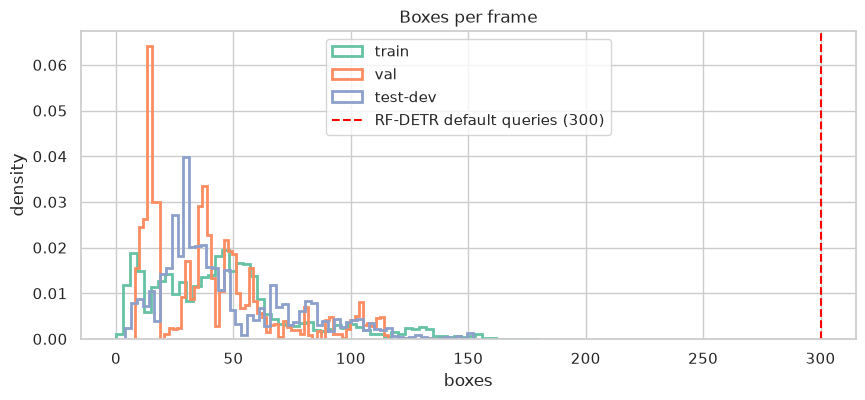

In [16]:
per_frame = (img_df[["split", "seq", "frame"]]
             .merge(obj.groupby(["split", "seq", "frame"]).size().rename("n").reset_index(), how="left")
             .fillna({"n": 0}))
per_frame["n"] = per_frame.n.astype(int)

log("Boxes per frame (cls 1-10)")
for split in SPLITS:
    n = per_frame[per_frame.split == split].n
    log(f"{split:<9} mean {n.mean():5.1f}  median {int(n.median()):>3}  p95 {int(n.quantile(.95)):>3}  "
        f"p99 {int(n.quantile(.99)):>3}  max {n.max():>3}", 1)
    log(f"frames with 0 boxes: {(n == 0).sum()}, >100: {(n > 100).sum()} ({pct((n > 100).sum(), len(n))}), "
        f">300: {(n > 300).sum()}", 2)

top = per_frame.sort_values("n", ascending=False).head(5)
log("Densest frames")
for r in top.itertuples():
    log(f"{r.split}/{r.seq}/{r.frame:07d}.jpg: {r.n} boxes", 1)

fig, ax = plt.subplots(figsize=(10, 4))
for split in SPLITS:
    ax.hist(per_frame[per_frame.split == split].n, bins=60, density=True, histtype="step", lw=2,
            label=split, color=PALETTE[split])
ax.axvline(300, c="red", ls="--", label="RF-DETR default queries (300)")
ax.set(title="Boxes per frame", xlabel="boxes", ylabel="density")
ax.legend()
save_fig(fig, "08_density")
plt.show()

**Nhận xét.**

Trung bình mỗi frame có 40 đến 46 box, frame đông nhất có 180 box ở train, 116 ở val và 152 ở test-dev, và khoảng 6 đến 8% số frame có trên 100 box. Không có frame nào vượt quá 300 box, nên số query mặc định của RF-DETR là đủ và không cần tăng `num_queries`, miễn là khi suy luận giữ lại top-300 thay vì top-100.

Với các mô hình khác cần chú ý giới hạn số box đầu ra. Faster R-CNN phải tăng `box_detections_per_img` từ mặc định 100, còn YOLO nên đặt `max_det` lớn hơn 180, nếu không sẽ mất box ở các frame đông.

## 9. Che khuất và bị cắt mép

[+] Occlusion share
    [-] train     none  54.3%  partial  40.3%  heavy   5.3%  truncated   4.3%
    [-] val       none  40.9%  partial  52.4%  heavy   6.6%  truncated   5.3%
    [-] test-dev  none  47.9%  partial  42.6%  heavy   9.5%  truncated   4.4%
    [-] Saved table 07_occlusion_class_train.csv


    [-] Saved figure 09_occlusion.png


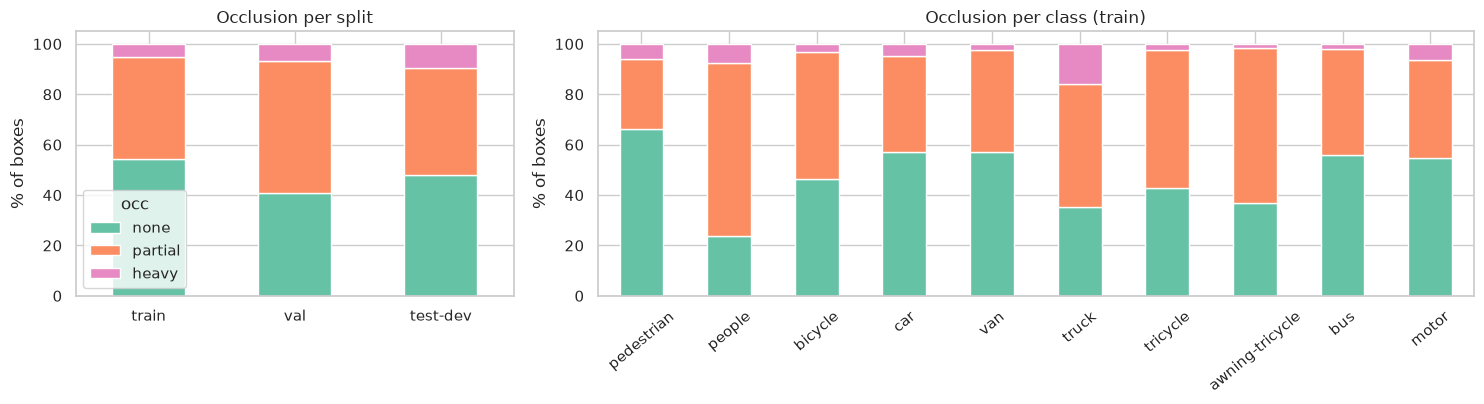

In [17]:
occ_names = {0: "none", 1: "partial", 2: "heavy"}
occ = obj.pivot_table(index="split", columns="occ", values="frame", aggfunc="size").reindex(SPLITS)
occ = (100 * occ.div(occ.sum(axis=1), axis=0)).rename(columns=occ_names)
trunc = obj.groupby("split").trunc.apply(lambda s: 100 * (s > 0).mean()).reindex(SPLITS)

log("Occlusion share")
for split in SPLITS:
    log(f"{split:<9} none {occ.loc[split, 'none']:5.1f}%  partial {occ.loc[split, 'partial']:5.1f}%  "
        f"heavy {occ.loc[split, 'heavy']:5.1f}%  truncated {trunc[split]:5.1f}%", 1)

occ_cls = obj[obj.split == "train"].pivot_table(index="cls_name", columns="occ", values="frame", aggfunc="size")
occ_cls = (100 * occ_cls.div(occ_cls.sum(axis=1), axis=0)).rename(columns=occ_names)
occ_cls = occ_cls.reindex([CLASS_NAMES[c] for c in OBJ_CLASSES])
save_table(occ_cls, "07_occlusion_class_train")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2]})
occ.plot.bar(stacked=True, ax=axes[0], color=["#66c2a5", "#fc8d62", "#e78ac3"])
axes[0].set(title="Occlusion per split", xlabel="", ylabel="% of boxes")
axes[0].tick_params(axis="x", rotation=0)
occ_cls.plot.bar(stacked=True, ax=axes[1], color=["#66c2a5", "#fc8d62", "#e78ac3"], legend=False)
axes[1].set(title="Occlusion per class (train)", xlabel="", ylabel="% of boxes")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout()
save_fig(fig, "09_occlusion")
plt.show()

**Nhận xét.**

Khoảng một nửa số box bị che một phần hoặc bị che nhiều, cụ thể là 45,7% ở train, 59,1% ở val và 52,1% ở test-dev. Test-dev có tỉ lệ che nặng cao nhất với 9,5%. Lớp khó nhất là `people`, với 69% box bị che một phần do thường ngồi trên xe hoặc đứng thành nhóm, và `truck` với 15,8% box bị che nặng.

Che khuất là nguyên nhân chính gây mất box và đổi ID khi tracking. Đây sẽ là luận điểm quan trọng khi so sánh các tracker có ReID như DeepSORT và BoT-SORT với các tracker chỉ dựa trên IoU.

## 10. Phân bố không gian của tâm box

    [-] Saved figure 10_spatial.png


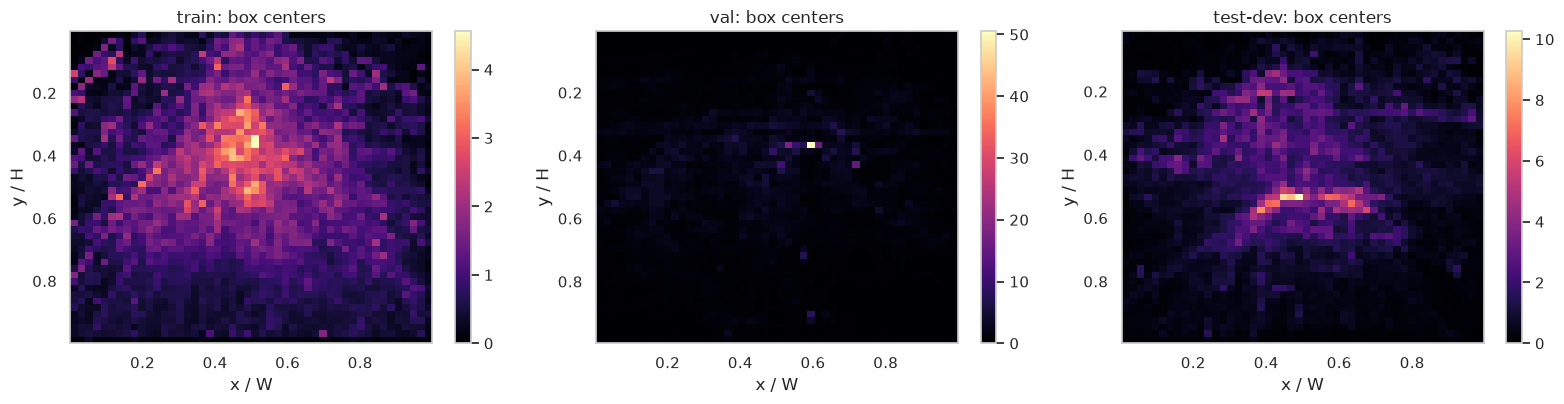

[+] Box centers by vertical third of the image


    [-] train     top 31.7%  middle 46.6%  bottom 21.7%
    [-] val       top 27.4%  middle 58.0%  bottom 14.7%


    [-] test-dev  top 31.5%  middle 52.5%  bottom 16.0%


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, split in zip(axes, SPLITS):
    o = obj[obj.split == split]
    h = ax.hist2d(o.cx.clip(0, 1), o.cy.clip(0, 1), bins=48, cmap="magma", density=True)
    ax.invert_yaxis()
    ax.set(title=f"{split}: box centers", xlabel="x / W", ylabel="y / H")
    fig.colorbar(h[3], ax=ax)
plt.tight_layout()
save_fig(fig, "10_spatial")
plt.show()

log("Box centers by vertical third of the image")
for split in SPLITS:
    o = obj[obj.split == split]
    t = pd.cut(o.cy, [-np.inf, 1 / 3, 2 / 3, np.inf], labels=["top", "middle", "bottom"]).value_counts(normalize=True)
    log(f"{split:<9} top {100 * t['top']:4.1f}%  middle {100 * t['middle']:4.1f}%  bottom {100 * t['bottom']:4.1f}%", 1)

**Nhận xét.**

Tâm box tập trung ở dải giữa ảnh (47 đến 58%) và nửa trên, rất ít ở đáy ảnh. Nguyên nhân là camera drone nhìn xiên, nên phần trên ảnh ở xa chứa nhiều đối tượng nhỏ và dày đặc, còn phần dưới ở gần chứa đối tượng lớn nhưng thưa.

Vì kích thước đối tượng phụ thuộc vào vị trí dọc trong ảnh, augmentation lật dọc sẽ tạo ra những cảnh phi thực tế và không nên dùng. Lật ngang thì vẫn an toàn.

## 11. Thống kê quỹ đạo (track)

Chỉ xét các lớp đối tượng (1–10). Mỗi track được xác định bởi `(split, seq, track_id)`.

In [19]:
tr = obj.groupby(["split", "seq", "track_id"]).agg(
    cls=("cls", "first"), n_cls=("cls", "nunique"), length=("frame", "size"),
    f_min=("frame", "min"), f_max=("frame", "max"),
).reset_index()
tr["span"] = tr.f_max - tr.f_min + 1
tr["gap_frames"] = tr.span - tr.length
tr["cls_name"] = tr.cls.map(CLASS_NAMES)

log("Track length (annotated frames per track)")
for split in SPLITS:
    t = tr[tr.split == split]
    log(f"{split:<9} {fmt(len(t)):>6} tracks  median {int(t.length.median()):>3}  mean {t.length.mean():5.1f}  "
        f"p95 {int(t.length.quantile(.95)):>4}  max {t.length.max():>4}", 1)
    log(f"short tracks (< 10 frames): {pct((t.length < 10).sum(), len(t))}, "
        f"tracks with gaps: {pct((t.gap_frames > 0).sum(), len(t))}, "
        f"tracks with class changes: {(t.n_cls > 1).sum()}", 2)

tr_cls = tr[tr.split == "train"].groupby("cls_name").agg(
    tracks=("length", "size"), median_length=("length", "median"),
    pct_with_gap=("gap_frames", lambda s: 100 * (s > 0).mean()),
).reindex([CLASS_NAMES[c] for c in OBJ_CLASSES])
save_table(tr_cls, "08_tracks_class_train")
tr_cls.style.format(precision=1)

[+] Track length (annotated frames per track)
    [-] train      7.342 tracks  median 103  mean 150.6  p95  414  max 1255
        [-] short tracks (< 10 frames): 4.3%, tracks with gaps: 6.9%, tracks with class changes: 229
    [-] val          758 tracks  median 124  mean 150.6  p95  379  max  978
        [-] short tracks (< 10 frames): 3.6%, tracks with gaps: 11.3%, tracks with class changes: 18
    [-] test-dev   2.293 tracks  median 100  mean 134.2  p95  328  max  766
        [-] short tracks (< 10 frames): 6.9%, tracks with gaps: 7.3%, tracks with class changes: 76
    [-] Saved table 08_tracks_class_train.csv


,tracks,median_length,pct_with_gap
cls_name,,,
pedestrian,1807,85.0,8.4
people,809,82.0,9.1
bicycle,299,107.0,9.7
car,2976,123.5,5.1
van,262,137.0,5.3
truck,148,165.5,7.4
tricycle,198,91.5,5.6
awning-tricycle,73,130.0,4.1
bus,51,157.0,3.9


In [20]:
o = obj.sort_values(["split", "seq", "track_id", "frame"])
nxt = o.groupby(["split", "seq", "track_id"]).shift(-1)
pair = o.assign(nf=nxt.frame, nx=nxt.x, ny=nxt.y, nw=nxt.w, nh=nxt.h).dropna(subset=["nf"])
pair = pair[pair.nf == pair.frame + 1]

ix1 = np.maximum(pair.x, pair.nx); iy1 = np.maximum(pair.y, pair.ny)
ix2 = np.minimum(pair.x + pair.w, pair.nx + pair.nw); iy2 = np.minimum(pair.y + pair.h, pair.ny + pair.nh)
inter = (ix2 - ix1).clip(lower=0) * (iy2 - iy1).clip(lower=0)
pair["iou"] = inter / (pair.w * pair.h + pair.nw * pair.nh - inter)
disp = np.hypot((pair.nx + pair.nw / 2) - (pair.x + pair.w / 2), (pair.ny + pair.nh / 2) - (pair.y + pair.h / 2))
pair["disp_px"] = disp
pair["disp_rel"] = disp / np.sqrt(pair.w * pair.h)

log(f"Consecutive-frame pairs analysed: {fmt(len(pair))}")
log("IoU of the same object between frame t and t+1")
for split in SPLITS:
    p = pair[pair.split == split]
    log(f"{split:<9} median IoU {p.iou.median():.3f}  IoU<0.5 {pct((p.iou < 0.5).sum(), len(p))}  "
        f"IoU<0.3 {pct((p.iou < 0.3).sum(), len(p))}  IoU=0 {pct((p.iou == 0).sum(), len(p))}", 1)
log("Center displacement per frame")
for split in SPLITS:
    p = pair[pair.split == split]
    log(f"{split:<9} median {p.disp_px.median():.1f}px ({p.disp_rel.median():.2f} box size)  "
        f"p95 {p.disp_px.quantile(.95):.1f}px ({p.disp_rel.quantile(.95):.2f} box size)", 1)

iou_cls = pair[pair.split == "train"].groupby("cls_name").agg(
    median_iou=("iou", "median"), pct_iou_lt_03=("iou", lambda s: 100 * (s < 0.3).mean()),
    median_disp_px=("disp_px", "median"), p95_disp_rel=("disp_rel", lambda s: s.quantile(.95)),
).reindex([CLASS_NAMES[c] for c in OBJ_CLASSES])
save_table(iou_cls, "09_motion_class_train")
iou_cls.style.format(precision=2)

[+] Consecutive-frame pairs analysed: 1.516.228
[+] IoU of the same object between frame t and t+1
    [-] train     median IoU 0.897  IoU<0.5 4.1%  IoU<0.3 1.6%  IoU=0 0.6%


    [-] val       median IoU 0.873  IoU<0.5 10.9%  IoU<0.3 4.2%  IoU=0 1.1%
    [-] test-dev  median IoU 0.875  IoU<0.5 7.1%  IoU<0.3 3.2%  IoU=0 0.9%
[+] Center displacement per frame


    [-] train     median 2.0px (0.04 box size)  p95 14.7px (0.26 box size)
    [-] val       median 2.5px (0.05 box size)  p95 27.0px (0.51 box size)
    [-] test-dev  median 1.8px (0.05 box size)  p95 13.5px (0.35 box size)


    [-] Saved table 09_motion_class_train.csv


,median_iou,pct_iou_lt_03,median_disp_px,p95_disp_rel
cls_name,,,,
pedestrian,0.86,3.08,2.06,0.32
people,0.80,3.06,3.00,0.37
bicycle,0.84,2.36,2.83,0.31
car,0.92,0.85,1.58,0.20
van,0.93,0.40,1.41,0.16
truck,0.94,0.59,1.50,0.14
tricycle,0.90,0.50,2.24,0.22
awning-tricycle,0.90,0.66,1.80,0.20
bus,0.94,0.06,3.00,0.10


    [-] Saved figure 11_tracks.png


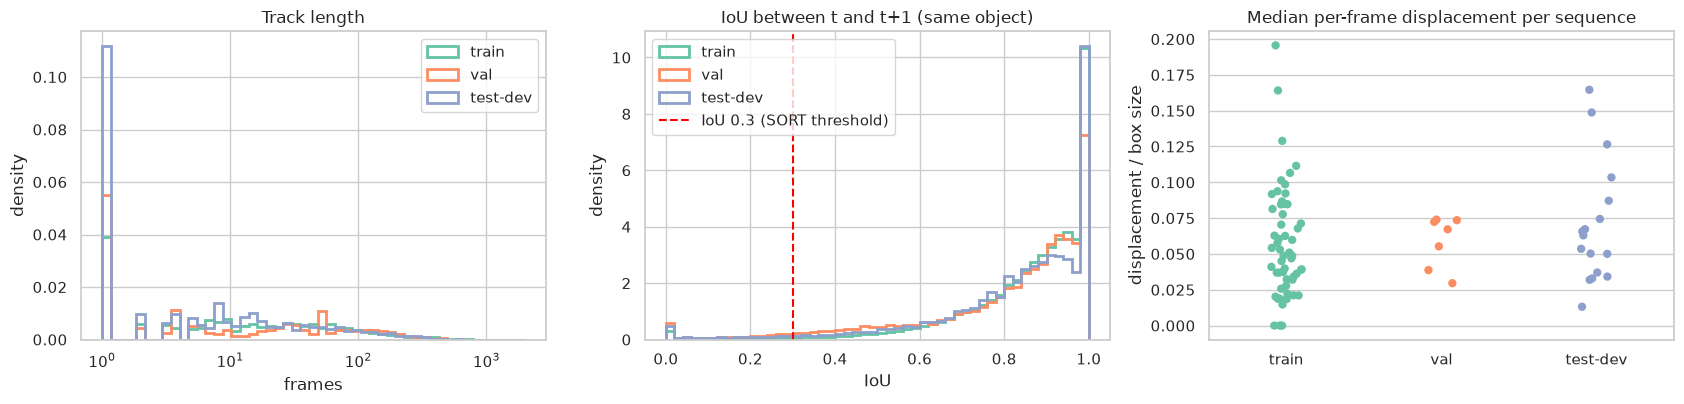

[+] Sequences with the fastest relative motion (median displacement / box size)
    [-] train/uav0000218_00001_v: 0.20
    [-] test-dev/uav0000249_02688_v: 0.16
    [-] train/uav0000289_06922_v: 0.16
    [-] test-dev/uav0000249_00001_v: 0.15
    [-] train/uav0000243_00001_v: 0.13


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for split in SPLITS:
    axes[0].hist(tr[tr.split == split].length, bins=np.logspace(0, 3.3, 50), density=True, histtype="step", lw=2,
                 label=split, color=PALETTE[split])
    axes[1].hist(pair[pair.split == split].iou, bins=50, density=True, histtype="step", lw=2, label=split,
                 color=PALETTE[split])
axes[0].set(xscale="log", title="Track length", xlabel="frames", ylabel="density")
axes[1].axvline(0.3, c="red", ls="--", label="IoU 0.3 (SORT threshold)")
axes[1].set(title="IoU between t and t+1 (same object)", xlabel="IoU", ylabel="density")
seq_motion = pair.groupby(["split", "seq"]).disp_rel.median().reset_index()
sns.stripplot(data=seq_motion, x="split", y="disp_rel", ax=axes[2], order=SPLITS, palette=PALETTE, size=6)
axes[2].set(title="Median per-frame displacement per sequence", xlabel="", ylabel="displacement / box size")
for a in axes[:2]:
    a.legend()
plt.tight_layout()
save_fig(fig, "11_tracks")
plt.show()

log("Sequences with the fastest relative motion (median displacement / box size)")
for r in seq_motion.sort_values("disp_rel", ascending=False).head(5).itertuples():
    log(f"{r.split}/{r.seq}: {r.disp_rel:.2f}", 1)

**Nhận xét.**

Các quỹ đạo khá dài, trung vị khoảng 100 đến 124 frame, và chỉ 4 đến 7% track ngắn hơn 10 frame. Có 7 đến 11% track bị đứt đoạn do đối tượng bị che hoặc ra khỏi khung hình rồi xuất hiện lại, nên giá trị `track_buffer` hoặc `max_age` bằng 30 frame là hợp lý và có thể thử thêm 60 khi dò tham số.

IoU giữa hai frame liên tiếp của cùng một đối tượng rất cao, trung vị khoảng 0,87 đến 0,90, và chỉ 1,6 đến 4,2% số cặp có IoU dưới 0,3. Điều này cho thấy nếu detector tốt thì các tracker dựa trên IoU như SORT, ByteTrack và OC-SORT đã đủ để liên kết phần lớn quỹ đạo, và sai số tracking chủ yếu sẽ đến từ việc detector bỏ sót box nhỏ chứ không phải từ chuyển động.

Val có chuyển động mạnh hơn train, với dịch chuyển p95 bằng 0,51 lần kích thước box so với 0,26 ở train. Một số chuỗi như `uav0000218_00001_v` và `uav0000249_*` có camera di chuyển nhanh, là nơi bù chuyển động camera của BoT-SORT có thể phát huy tác dụng. Ngoài ra có 229 track ở train đổi lớp giữa chừng, chủ yếu giữa `pedestrian` và `people`, cần lưu ý khi chạy tracker theo từng lớp.

## 12. Vùng ignored (lớp 0)

In [22]:
ign_frame = ign.groupby(["split", "seq", "frame"]).agg(n=("x", "size"), area=("rel_area", "sum")).reset_index()
log("Ignored regions")
for split in SPLITS:
    g = ign_frame[ign_frame.split == split]
    n_frames = (img_df.split == split).sum()
    log(f"{split:<9} {fmt(int(g.n.sum())):>6} regions in {pct(len(g), n_frames)} of frames  "
        f"area/frame median {100 * g.area.median():.1f}%  p95 {100 * g.area.quantile(.95):.1f}%  max {100 * g.area.max():.1f}%", 1)

# objects whose center lies inside an ignored region
m = obj[["split", "seq", "frame", "x", "y", "w", "h"]].reset_index().merge(
    ign[["split", "seq", "frame", "x", "y", "w", "h"]], on=["split", "seq", "frame"], suffixes=("", "_i"))
cx, cy = m.x + m.w / 2, m.y + m.h / 2
inside = (cx >= m.x_i) & (cx <= m.x_i + m.w_i) & (cy >= m.y_i) & (cy <= m.y_i + m.h_i)
inside_ids = set(m.loc[inside, "index"])
log("Object boxes whose center falls inside an ignored region")
for split in SPLITS:
    idx = obj.index[obj.split == split]
    k = sum(i in inside_ids for i in idx)
    log(f"{split:<9} {fmt(k)} ({pct(k, len(idx))})", 1)

[+] Ignored regions
    [-] train     62.369 regions in 72.7% of frames  area/frame median 1.7%  p95 11.6%  max 38.5%
    [-] val        3.994 regions in 50.4% of frames  area/frame median 1.4%  p95 9.5%  max 11.1%
    [-] test-dev  23.472 regions in 85.8% of frames  area/frame median 2.6%  p95 11.2%  max 15.6%


[+] Object boxes whose center falls inside an ignored region
    [-] train     11.528 (1.0%)
    [-] val       1.228 (1.1%)


    [-] test-dev  3.570 (1.2%)


**Nhận xét.**

Vùng ignored xuất hiện trong 50 đến 86% số frame nhưng chỉ chiếm diện tích nhỏ, trung vị 1,4 đến 2,6% mỗi frame và lớn nhất 38,5%. Khoảng 1% box đối tượng có tâm nằm trong vùng ignored, cho thấy vùng này không có nghĩa là không có đối tượng mà chỉ là không được gán nhãn đầy đủ.

Khi train nên bỏ vùng ignored khỏi nhãn nhưng không tô đen ảnh. Khi đánh giá mAP và tracking phải lọc bỏ các detection rơi vào vùng ignored, nếu không các detection đúng ở đó sẽ bị tính là false positive.

## 13. Chất lượng nhãn

In [23]:
checks = {}
o = ann_all[ann_all.cls.isin(OBJ_CLASSES)]
checks["zero or negative size"] = (o.w <= 0) | (o.h <= 0)
checks["outside image (any side)"] = (o.x < 0) | (o.y < 0) | (o.x + o.w > o.img_w) | (o.y + o.h > o.img_h)
checks["tiny (min side < 4px)"] = np.minimum(o.w, o.h) < 4
checks["extreme aspect (>10 or <0.1)"] = (o.aspect > 10) | (o.aspect < 0.1)
checks["score = 0 on object class"] = o.score == 0
checks["duplicate (seq, frame, id)"] = o.duplicated(["split", "seq", "frame", "track_id"], keep=False)
checks["exact duplicate box"] = o.duplicated(["split", "seq", "frame", "x", "y", "w", "h"], keep=False)
checks["frame index > sequence length"] = o.frame > o.join(seq_res.set_index(["split", "seq"]).n_frames,
                                                          on=["split", "seq"]).n_frames

quality = pd.DataFrame({k: v.groupby(o.split).sum() for k, v in checks.items()}).T.reindex(columns=SPLITS).fillna(0).astype(int)
save_table(quality, "10_label_quality")
log("Label quality checks (object classes 1-10)")
for name, r in quality.iterrows():
    log(f"{name:<32} " + "  ".join(f"{s}: {fmt(int(r[s])):>6}" for s in SPLITS), 1)

out = o[checks["outside image (any side)"]]
if len(out):
    over = np.maximum.reduce([-out.x, -out.y, out.x + out.w - out.img_w, out.y + out.h - out.img_h])
    log(f"Out-of-image boxes exceed the border by median {np.median(over):.0f}px, max {np.max(over):.0f}px")
quality

    [-] Saved table 10_label_quality.csv
[+] Label quality checks (object classes 1-10)
    [-] zero or negative size            train:      0  val:      0  test-dev:      0
    [-] outside image (any side)         train:     31  val:      0  test-dev:      3
    [-] tiny (min side < 4px)            train:      0  val:      0  test-dev:      0
    [-] extreme aspect (>10 or <0.1)     train:    100  val:     26  test-dev:      9
    [-] score = 0 on object class        train:      0  val:      0  test-dev:      0
    [-] duplicate (seq, frame, id)       train:      0  val:      0  test-dev:      0
    [-] exact duplicate box              train:      0  val:      0  test-dev:      2
    [-] frame index > sequence length    train:      0  val:      0  test-dev:      0
[+] Out-of-image boxes exceed the border by median 1px, max 2px


split,train,val,test-dev
zero or negative size,0,0,0
outside image (any side),31,0,3
tiny (min side < 4px),0,0,0
extreme aspect (>10 or <0.1),100,26,9
score = 0 on object class,0,0,0
"duplicate (seq, frame, id)",0,0,0
exact duplicate box,0,0,2
frame index > sequence length,0,0,0


**Nhận xét.**

Nhãn rất sạch. Không có box kích thước bằng 0, không có ID trùng trong cùng một frame, không có box đối tượng nào mang `score` bằng 0 và không có box nào có cạnh dưới 4 px ở ảnh gốc.

Có 34 box vượt ra ngoài mép ảnh (31 ở train và 3 ở test-dev), nhưng chỉ lệch 1 đến 2 px, nên chỉ cần clip về trong ảnh khi chuyển sang COCO hoặc YOLO. 135 box có tỉ lệ khung hình cực đoan thường là đối tượng bị cắt ở mép ảnh và có thể giữ nguyên.

## 14. Độ dư thừa giữa các frame và ảnh hưởng của lấy mẫu 1/2

In [24]:
import cv2

rng = np.random.default_rng(0)
LAGS = [1, 2, 5, 10, 30]


def frame_diff(args):
    seq_dir, f0, lags = args
    def load(f):
        im = cv2.imread(str(seq_dir / f"{f:07d}.jpg"), cv2.IMREAD_GRAYSCALE)
        return cv2.resize(im, (240, 135), interpolation=cv2.INTER_AREA).astype(np.float32)
    a = load(f0)
    return [float(np.abs(a - load(f0 + l)).mean()) for l in lags]


jobs = []
for r in seq_res[seq_res.split == "train"].itertuples():
    d = DATA_ROOT / "VisDrone2019-MOT-train" / "sequences" / r.seq
    for f0 in rng.integers(1, r.n_frames - max(LAGS), size=5):
        jobs.append((d, int(f0), LAGS))
with ProcessPoolExecutor(N_WORKERS) as ex:
    diffs = np.array(list(ex.map(frame_diff, jobs)))

log(f"Mean absolute pixel difference (grayscale 0-255, 240x135) over {len(jobs)} samples")
for l, v in zip(LAGS, diffs.mean(axis=0)):
    log(f"lag {l:>2} frames: {v:5.2f}", 1)

[+] Mean absolute pixel difference (grayscale 0-255, 240x135) over 280 samples
    [-] lag  1 frames:  4.67
    [-] lag  2 frames:  7.11
    [-] lag  5 frames: 11.49
    [-] lag 10 frames: 15.30
    [-] lag 30 frames: 21.60


In [25]:
train_obj = obj[obj.split == "train"]
sub = train_obj[train_obj.frame % 2 == 1]
cmp = pd.DataFrame({
    "full": train_obj.cls_name.value_counts(normalize=True) * 100,
    "stride 2": sub.cls_name.value_counts(normalize=True) * 100,
}).reindex([CLASS_NAMES[c] for c in OBJ_CLASSES])
cmp["diff (pp)"] = cmp["stride 2"] - cmp["full"]

n_full = (img_df.split == "train").sum()
n_sub = ((img_df.split == "train") & (img_df.frame % 2 == 1)).sum()
log("Train subsampling with stride 2 (odd frames)")
log(f"images: {fmt(int(n_full))} -> {fmt(int(n_sub))}", 1)
log(f"boxes:  {fmt(len(train_obj))} -> {fmt(len(sub))}", 1)
log(f"tracks kept: {sub.groupby(['seq', 'track_id']).ngroups} / {train_obj.groupby(['seq', 'track_id']).ngroups}", 1)
log(f"max change in class share: {cmp['diff (pp)'].abs().max():.3f} percentage points", 1)
save_table(cmp, "11_stride2_class_share")
cmp.style.format(precision=3)

[+] Train subsampling with stride 2 (odd frames)
    [-] images: 24.201 -> 12.114
    [-] boxes:  1.105.516 -> 553.391
    [-] tracks kept: 7312 / 7342
    [-] max change in class share: 0.016 percentage points
    [-] Saved table 11_stride2_class_share.csv


,full,stride 2,diff (pp)
cls_name,,,
pedestrian,21.194,21.201,0.006
people,8.539,8.545,0.007
bicycle,3.641,3.643,0.002
car,45.707,45.691,-0.016
van,4.246,4.247,0.001
truck,2.759,2.759,0.000
tricycle,2.563,2.565,0.002
awning-tricycle,1.177,1.177,-0.000
bus,0.873,0.873,0.000


**Nhận xét.**

Sai khác pixel giữa hai frame liên tiếp rất nhỏ, chỉ khoảng 4,7 trên thang 255, và tăng dần lên 15,3 khi cách nhau 10 frame. Các frame liên tiếp gần như trùng nhau, nên dùng toàn bộ frame chủ yếu làm tăng thời gian train mà không bổ sung nhiều thông tin.

Lấy mẫu stride 2 giảm số ảnh train từ 24.201 xuống 12.114 nhưng vẫn giữ 99,6% số track, và tỉ lệ các lớp gần như không đổi với mức lệch tối đa 0,016 điểm phần trăm. Đây là căn cứ định lượng cho quyết định lấy mẫu 1/2 trong kế hoạch. Cũng vì frame liên tiếp gần như giống nhau, tuyệt đối không được xáo trộn frame rồi chia lại train và val, mà phải giữ nguyên ranh giới chuỗi của split chính thức.

## 15. Ảnh minh họa

    [-] Saved figure 15_samples.png


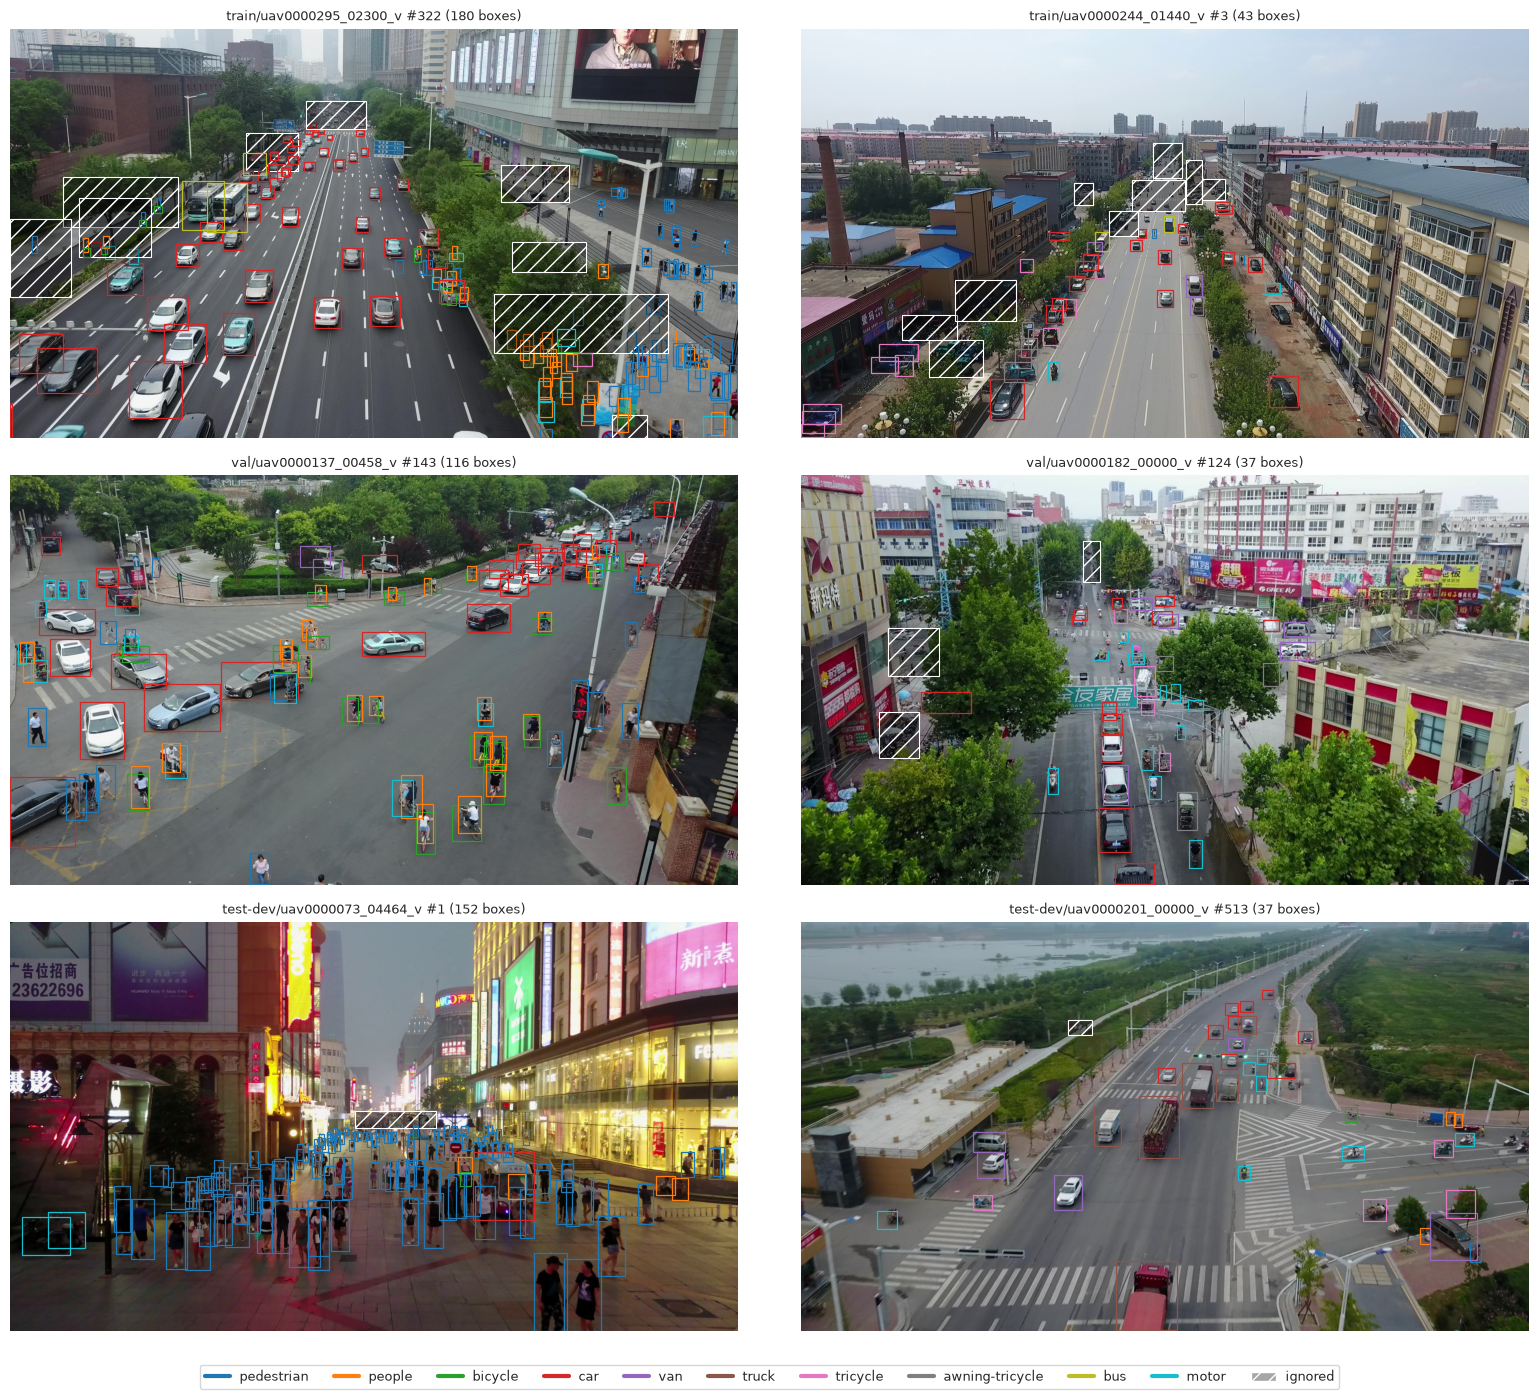

In [26]:
cmap = dict(zip(OBJ_CLASSES, sns.color_palette("tab10", 10)))


def show_frame(ax, split, seq, frame):
    im = Image.open(DATA_ROOT / f"VisDrone2019-MOT-{split}" / "sequences" / seq / f"{frame:07d}.jpg")
    ax.imshow(im)
    a = ann_all[(ann_all.split == split) & (ann_all.seq == seq) & (ann_all.frame == frame)]
    for r in a.itertuples():
        if r.cls == 0:
            ax.add_patch(plt.Rectangle((r.x, r.y), r.w, r.h, fill=True, fc=(0, 0, 0, 0.35), ec="white", hatch="//", lw=0.8))
        elif r.cls in cmap:
            ax.add_patch(plt.Rectangle((r.x, r.y), r.w, r.h, fill=False, ec=cmap[r.cls], lw=0.9))
    ax.set_title(f"{split}/{seq} #{frame} ({(a.cls.isin(OBJ_CLASSES)).sum()} boxes)", fontsize=9)
    ax.axis("off")


picks = []
for split in SPLITS:
    pf = per_frame[per_frame.split == split].sort_values("n")
    picks.append((split, *pf.iloc[-1][["seq", "frame"]]))            # densest frame
    picks.append((split, *pf.iloc[len(pf) // 2][["seq", "frame"]]))  # typical frame
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for ax, (s, q, f) in zip(axes.flat, picks):
    show_frame(ax, s, q, int(f))
handles = [plt.Line2D([], [], color=cmap[c], lw=3, label=CLASS_NAMES[c]) for c in OBJ_CLASSES]
handles.append(plt.Rectangle((0, 0), 1, 1, fc=(0, 0, 0, 0.35), ec="white", hatch="//", label="ignored"))
fig.legend(handles=handles, loc="lower center", ncol=11, fontsize=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
save_fig(fig, "15_samples")
plt.show()

    [-] Saved figure 15_class_crops.png


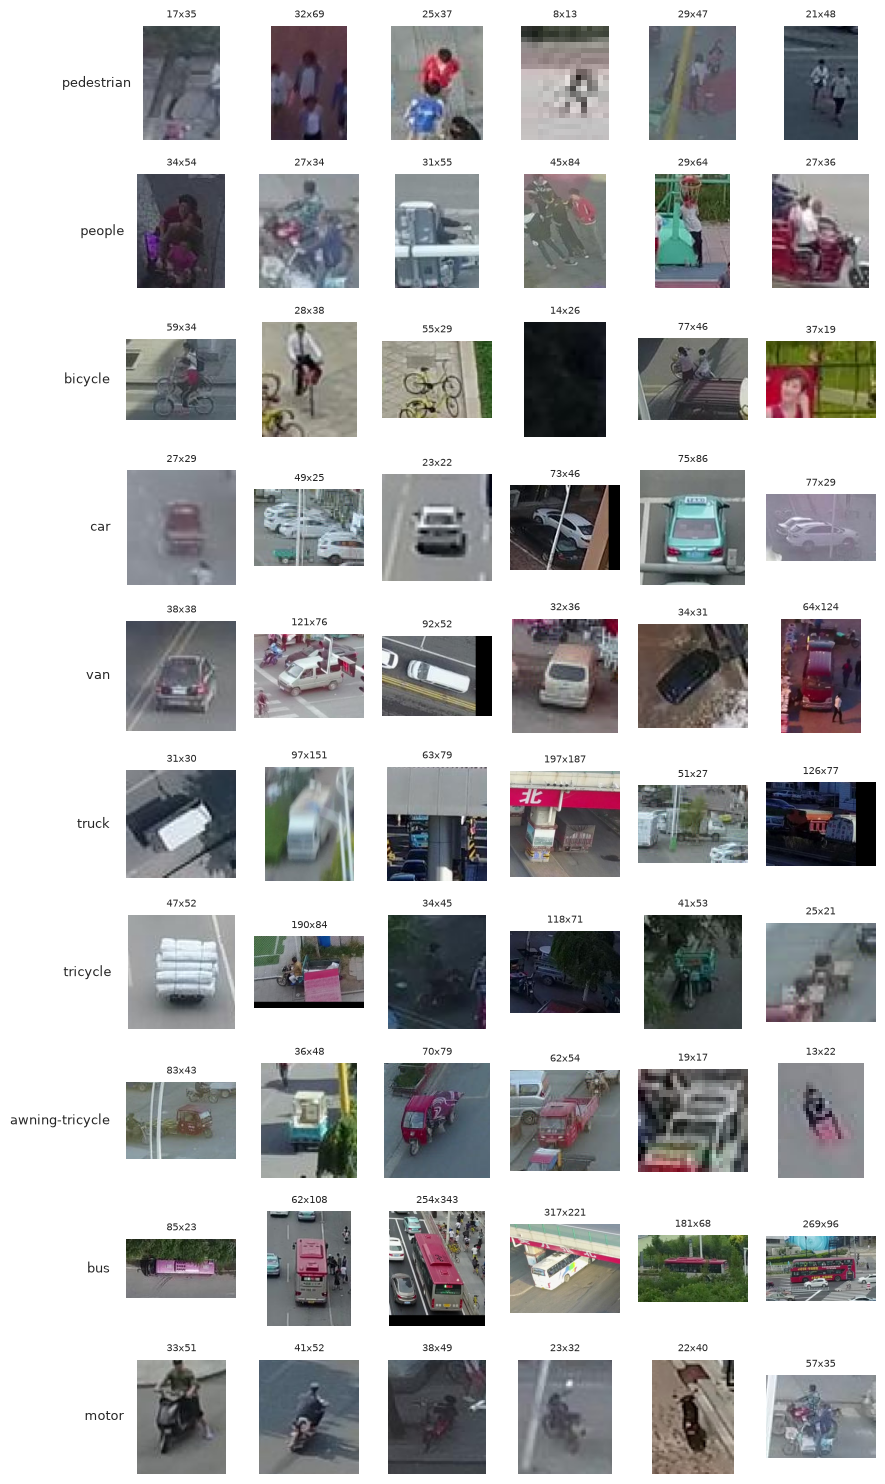

In [27]:
crops = obj[(obj.split == "train")].groupby("cls").sample(6, random_state=0)
fig, axes = plt.subplots(len(OBJ_CLASSES), 6, figsize=(9, 15))
for (c, g), row in zip(crops.groupby("cls"), axes):
    for r, ax in zip(g.itertuples(), row):
        im = Image.open(DATA_ROOT / "VisDrone2019-MOT-train" / "sequences" / r.seq / f"{r.frame:07d}.jpg")
        pad = max(r.w, r.h) * 0.3
        ax.imshow(im.crop((r.x - pad, r.y - pad, r.x + r.w + pad, r.y + r.h + pad)))
        ax.set_title(f"{r.w}x{r.h}", fontsize=7)
        ax.axis("off")
    row[0].text(-0.15, 0.5, CLASS_NAMES[c], transform=row[0].transAxes, ha="right", va="center", fontsize=9)
plt.tight_layout()
save_fig(fig, "15_class_crops")
plt.show()

**Nhận xét.**

Ảnh minh họa phản ánh đúng các đặc điểm đã thống kê, với cảnh đô thị đông đúc, đối tượng ở xa rất nhỏ và vùng ignored thường là bãi đỗ xe hoặc đám đông ở xa. Dữ liệu còn có cảnh ban đêm hoặc thiếu sáng với mật độ người rất cao như `test-dev/uav0000073_04464_v`, là trường hợp khó cho cả detection lẫn tracking.

Ảnh crop theo lớp cho thấy `people` với `pedestrian` và `tricycle` với `awning-tricycle` rất khó phân biệt ở kích thước nhỏ, nên việc mô hình nhầm giữa các cặp lớp này là điều dễ hiểu khi phân tích confusion matrix.

## 16. Tổng kết

In [28]:
summary = {
    "frames (train/val/test-dev)": "/".join(fmt(int(overview.loc[s, "frames"])) for s in SPLITS),
    "boxes cls 1-10": "/".join(fmt(int(overview.loc[s, "boxes"])) for s in SPLITS),
    "tracks": "/".join(fmt(int(overview.loc[s, "tracks"])) for s in SPLITS),
    "max boxes per frame": "/".join(str(per_frame[per_frame.split == s].n.max()) for s in SPLITS),
    "small boxes (orig)": "/".join(f"{size_pct.loc[s, 'small']:.1f}%" for s in SPLITS),
    "min side < 8px @576": "/".join(f"{resized.loc[(576, s), 'min side < 8px']:.1f}%" for s in SPLITS),
    "min side < 8px @1024": "/".join(f"{resized.loc[(1024, s), 'min side < 8px']:.1f}%" for s in SPLITS),
    "train imbalance (max/min class)": f"{imb:.0f}x",
    "IoU(t,t+1) < 0.3": "/".join(pct((pair[pair.split == s].iou < 0.3).sum(), (pair.split == s).sum()) for s in SPLITS),
    "out-of-image boxes": "/".join(str(int(quality.loc["outside image (any side)", s])) for s in SPLITS),
}
log("Key numbers (train / val / test-dev)")
for k, v in summary.items():
    log(f"{k:<34} {v}", 1)
json.dump(summary, open(TABLE_DIR / "summary.json", "w"), indent=2, ensure_ascii=False)

[+] Key numbers (train / val / test-dev)
    [-] frames (train/val/test-dev)        24.201/2.846/6.635
    [-] boxes cls 1-10                     1.105.516/114.132/307.799
    [-] tracks                             7.342/758/2.293
    [-] max boxes per frame                180/116/152
    [-] small boxes (orig)                 24.9%/19.2%/47.8%
    [-] min side < 8px @576                27.9%/24.3%/24.3%
    [-] min side < 8px @1024               4.3%/5.3%/4.7%
    [-] train imbalance (max/min class)    52x
    [-] IoU(t,t+1) < 0.3                   1.6%/4.2%/3.2%
    [-] out-of-image boxes                 31/0/3


**Nhận xét.**

Dữ liệu VisDrone2019-MOT đầy đủ, nhất quán và có nhãn sạch, chỉ cần clip 34 box vượt mép ảnh khi chuyển định dạng. Thách thức lớn nhất là đối tượng rất nhỏ và dày đặc, trong đó test-dev còn nhỏ hơn train với 47,8% box thuộc nhóm small. Dữ liệu mất cân bằng lớp khoảng 52 lần, và hai lớp tracking là `bus` và `truck` có rất ít mẫu. Chuyển động giữa các frame nhỏ, nên chất lượng tracking sẽ phụ thuộc chủ yếu vào detector.

Về huấn luyện, nên tăng input của RF-DETR lên khoảng 896 đến 1024 nếu VRAM cho phép và luôn báo cáo AP_small. Giới hạn số box đầu ra cần đủ lớn, cụ thể là giữ 300 query cho RF-DETR, đặt `box_detections_per_img` bằng 1000 cho Faster R-CNN và `max_det` từ 300 trở lên cho YOLO. Tập train nên lấy mẫu stride 2 và giữ nguyên split theo chuỗi.

Về tiền xử lý nhãn, cần bỏ vùng ignored khỏi nhãn train nhưng không tô đen ảnh, clip các box vượt mép, ghi kích thước theo từng ảnh và không resize trước toàn bộ dataset. Augmentation nên dùng lật ngang và tránh lật dọc. Baseline giữ nguyên phân bố lớp, chỉ thử repeat-factor sampling sau nếu cần.

Về đánh giá, vì val nhỏ và dao động nên chọn checkpoint theo mAP trung bình và xem xu hướng qua nhiều epoch. mAP trên test-dev sẽ thấp hơn val, và có thể giải thích điều này bằng tỉ lệ box nhỏ cao hơn. Detection rơi vào vùng ignored phải được lọc trước khi tính chỉ số.